# Load and Clean Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
import os


wdf = pd.read_csv("world-data-2023.csv")

tdf = pd.read_csv("average-annual-surface-temperature.csv")

tdf_clean = tdf.copy()

wdf_clean = wdf.copy()

wdf_clean = wdf_clean.drop(columns=[
    'Abbreviation', 'Armed Forces size', 'Calling Code', 'CPI', 'CPI Change (%)',
    'Capital/Major City', 'Currency-Code', 'Gasoline Price',
    'GDP', 'Gross primary education enrollment (%)',
    'Gross tertiary education enrollment (%)',
    'Infant mortality', 'Largest city', 'Maternal mortality ratio',
    'Minimum wage', 'Official language',
    'Out of pocket health expenditure', 'Physicians per thousand',
    'Population: Labor force participation (%)', 'Tax revenue (%)',
    'Total tax rate', 'Unemployment rate'
])

tdf_clean = tdf_clean.drop(columns=['Code'])

tdf_clean = tdf_clean[tdf_clean['Year'] == 2023]

rename_countries = {
    "Bahamas": "The Bahamas",
    "Cote d'Ivoire": "Ivory Coast",
    "Côte d'Ivoire": "Ivory Coast",
    "Congo": "Republic of the Congo",
    "Democratic Republic of Congo": "Democratic Republic of the Congo",
    "Czechia": "Czech Republic",
    "Gambia": "The Gambia",
    "Ireland": "Republic of Ireland",
    "Palestine": "Palestinian National Authority",
    "Micronesia (country)": "Federated States of Micronesia"
}


tdf_clean["Country"] = tdf_clean["Country"].replace(rename_countries)


df = pd.merge(tdf_clean, wdf_clean, on='Country', how='inner')

numeric_columns = [
    'Latitude',
    'Longitude',
    'Forested Area (%)',
    'Agricultural Land( %)',
    'Co2-Emissions',
    'Density\r\n(P/Km2)',
    'Land Area(Km2)',
    'Birth Rate',
    'Fertility Rate',
    'Life expectancy',
    'Population',
    'Urban_population'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str)
        .str.replace(',', '', regex=False)
        .str.replace('%', '', regex=False),
        errors='coerce'
    )

df.to_csv("cleaned_data.csv", index=False)


print("Original country data:", wdf.shape)
print("Original temperature data:", tdf.shape)
print("Cleaned data:", df.shape)
print(df["Average surface temperature"].describe())

with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    print(df)


Original country data: (195, 35)
Original temperature data: (18318, 4)
Cleaned data: (176, 15)
count    176.000000
mean      19.702272
std        7.981907
min       -2.585444
25%       12.664335
50%       22.927892
75%       26.314512
max       29.533531
Name: Average surface temperature, dtype: float64
                              Country  Year  Average surface temperature  \
0                         Afghanistan  2023                    13.836377   
1                             Albania  2023                    13.822665   
2                             Algeria  2023                    24.873968   
3                             Andorra  2023                     7.266988   
4                              Angola  2023                    22.796457   
5                 Antigua and Barbuda  2023                    26.694235   
6                           Argentina  2023                    15.652064   
7                             Armenia  2023                     8.116077   
8          

# Training Model

Training rows: 140
Testing rows: 36
Baseline temperature: 20.067873754285714
                 Country  Actual Temperature  Predicted Temperature  Difference
                 Austria            8.280238              10.618791    2.338553
                 Bahrain           26.894918              27.036736    0.141818
                 Belgium           11.481215              11.024084    0.457132
                  Belize           26.619013              23.341680    3.277333
                  Bhutan            9.026128              17.439859    8.413731
                 Bolivia           21.484540              22.950674    1.466134
                Bulgaria           12.954609              12.949223    0.005386
                  Canada           -1.805844               6.435990    8.241833
              Cape Verde           23.760862              25.677502    1.916640
Central African Republic           26.717813              28.482557    1.764744
                    Cuba           26.29547

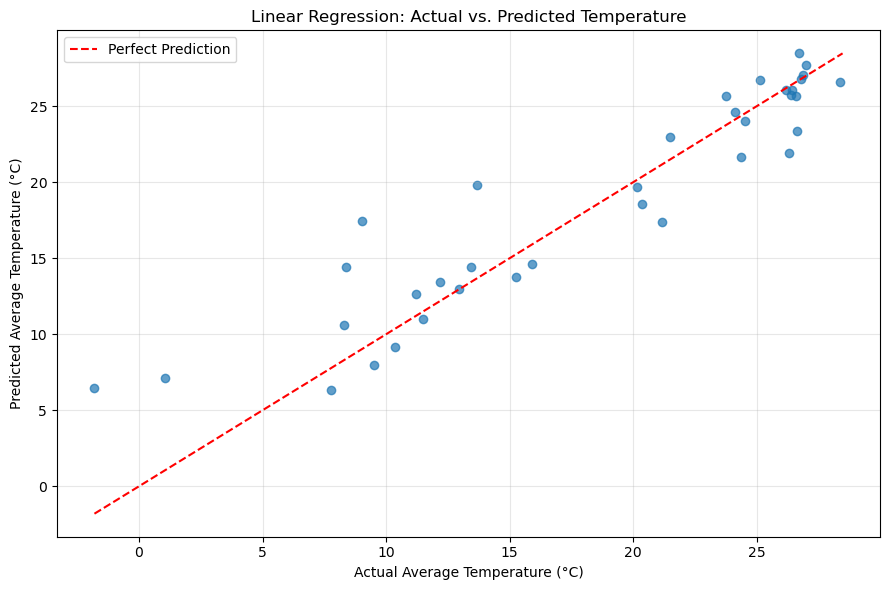

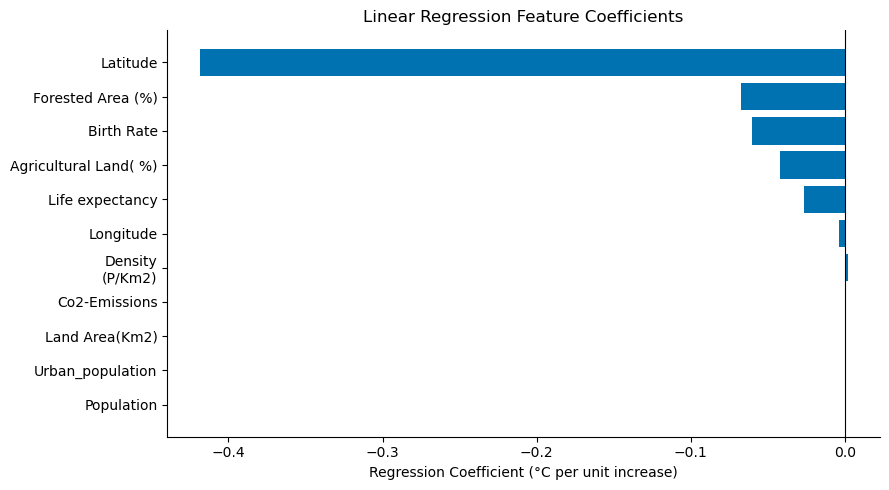

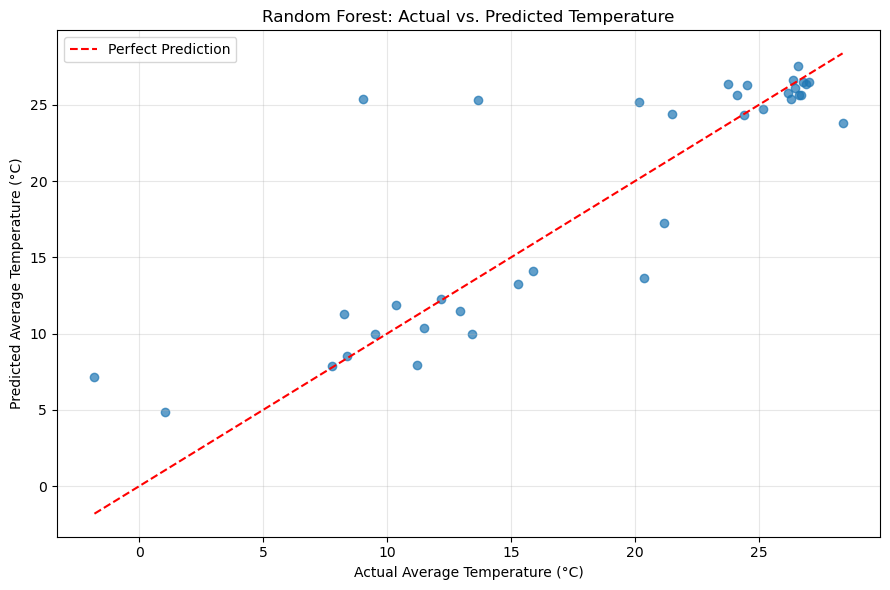

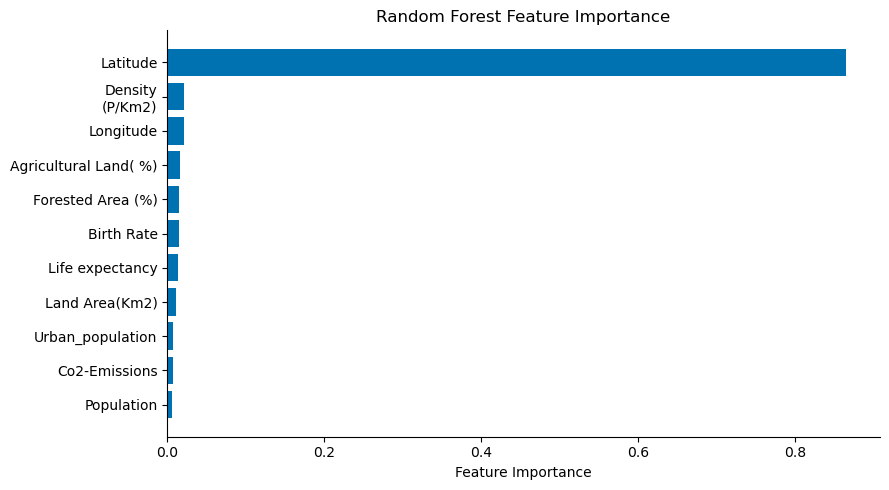

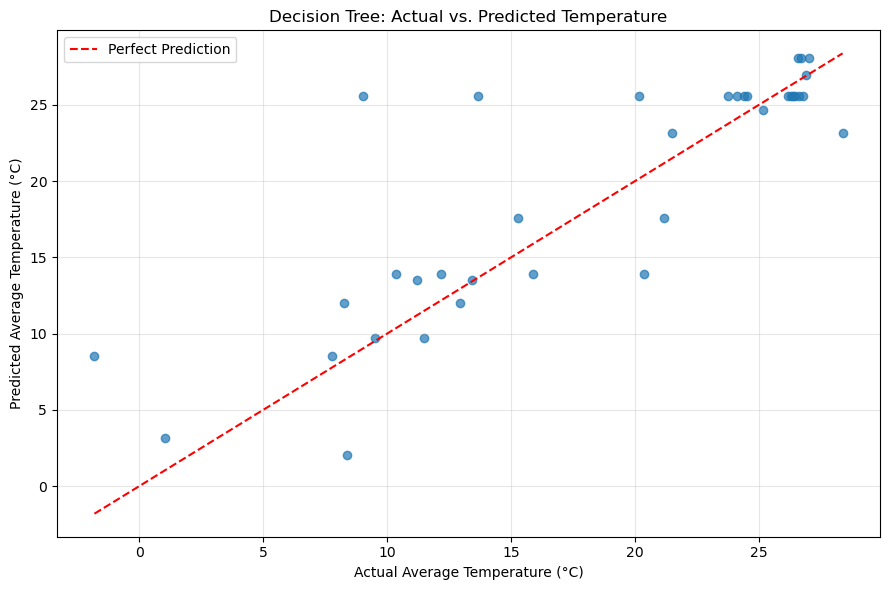

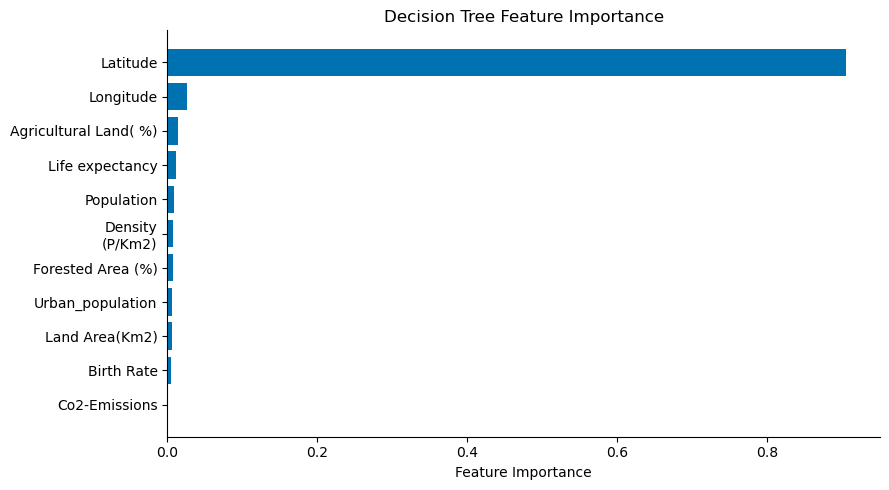

In [2]:

features = [
    'Latitude',
    'Longitude',
    'Forested Area (%)',
    'Agricultural Land( %)',
    'Co2-Emissions',
    'Density\r\n(P/Km2)',
    'Land Area(Km2)',
    'Birth Rate',
    'Life expectancy',
    'Population',
    'Urban_population'
]

target = 'Average surface temperature'

df['Latitude'] = df['Latitude'].abs()

df = df.dropna(subset=[target])

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

for col in features:
    mean = X_train[col].mean()
    X_train[col] = X_train[col].fillna(mean)
    X_test[col] = X_test[col].fillna(mean)

baseline_pred = np.full(len(y_test), y_train.mean())
print("Training rows:", len(y_train))
print("Testing rows:", len(y_test))
print("Baseline temperature:", y_train.mean())

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

with open("results/regression_data.txt", "w", encoding="utf-8") as file:
    file.write(f"MAE: {mean_absolute_error(y_test, y_pred)}\n")
    file.write(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred))}\n")
    file.write(f"R²: {r2_score(y_test, y_pred)}\n")

results = pd.DataFrame({
    'Country': df.loc[y_test.index, 'Country'],
    'Actual Temperature': y_test,
    'Predicted Temperature': y_pred
})

results['Difference'] = (
    results['Actual Temperature'] -
    results['Predicted Temperature']
).abs()

results = results.sort_values('Country')

print(results.to_string(index=False))


fig1, ax1 = plt.subplots(figsize=(9, 6))

ax1.scatter(y_test, y_pred, alpha=0.7)

min_temp = min(y_test.min(), y_pred.min())
max_temp = max(y_test.max(), y_pred.max())

ax1.plot(
    [min_temp, max_temp],
    [min_temp, max_temp],
    'r--',
    label='Perfect Prediction'
)

ax1.set_xlabel('Actual Average Temperature (°C)')
ax1.set_ylabel('Predicted Average Temperature (°C)')
ax1.set_title('Linear Regression: Actual vs. Predicted Temperature')
ax1.legend()
ax1.grid(alpha=0.3)

fig1.tight_layout()

fig1.savefig(
    os.path.join("figures", "fig1_model_vs_actual.png"),
    dpi=150
)

plt.show()


linear_importance = pd.Series(
    model.coef_,
    index=X.columns.str.replace("\r", "", regex=False)
).sort_values(key=abs)


fig2, ax2 = plt.subplots(figsize=(9, 5))

ax2.barh(
    linear_importance.index,
    linear_importance.values,
    color="#0072B2"
)


ax2.set_title("Linear Regression Feature Coefficients")
ax2.set_xlabel("Regression Coefficient (°C per unit increase)")

ax2.axvline(x=0, color="black", linewidth=0.8)

for side in ["top", "right"]:
    ax2.spines[side].set_visible(False)

fig2.tight_layout()

fig2.savefig(
    os.path.join("figures", "fig2_feature_importance.png"),
    dpi=150
)

plt.show()

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

with open("results/random_forest_data.txt", "w", encoding="utf-8") as file:
    file.write(f"MAE: {mean_absolute_error(y_test, rf_pred)}\n")
    file.write(f"RMSE: {np.sqrt(mean_squared_error(y_test, rf_pred))}\n")
    file.write(f"R²: {r2_score(y_test, rf_pred)}\n")


fig3, ax3 = plt.subplots(figsize=(9, 6))

ax3.scatter(y_test, rf_pred, alpha=0.7)

min_temp = min(y_test.min(), rf_pred.min())
max_temp = max(y_test.max(), rf_pred.max())

ax3.plot(
    [min_temp, max_temp],
    [min_temp, max_temp],
    'r--',
    label='Perfect Prediction'
)

ax3.set_xlabel('Actual Average Temperature (°C)')
ax3.set_ylabel('Predicted Average Temperature (°C)')
ax3.set_title('Random Forest: Actual vs. Predicted Temperature')
ax3.legend()
ax3.grid(alpha=0.3)

fig3.tight_layout()

fig3.savefig(
    os.path.join("figures", "fig3_rf_linear_prediction.png"),
    dpi=150
)

plt.show()

rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns.str.replace("\r", "", regex=False)
).sort_values()

fig4, ax4 = plt.subplots(figsize=(9, 5))

ax4.barh(
    rf_importance.index,
    rf_importance.values,
    color="#0072B2"
)

ax4.set_title("Random Forest Feature Importance")
ax4.set_xlabel("Feature Importance")

for side in ["top", "right"]:
    ax4.spines[side].set_visible(False)

fig4.tight_layout()

fig4.savefig(
    os.path.join("figures", "fig4_feature_importance.png"),
    dpi=150
)

plt.show()


dt_model = DecisionTreeRegressor(max_depth=6, random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

with open("results/decision_tree_data.txt", "w", encoding="utf-8") as file:
    file.write(f"MAE: {mean_absolute_error(y_test, dt_pred)}\n")
    file.write(f"RMSE: {np.sqrt(mean_squared_error(y_test, dt_pred))}\n")
    file.write(f"R²: {r2_score(y_test, dt_pred)}\n")


fig5, ax5 = plt.subplots(figsize=(9, 6))

ax5.scatter(y_test, dt_pred, alpha=0.7)

min_temp = min(y_test.min(), dt_pred.min())
max_temp = max(y_test.max(), dt_pred.max())

ax5.plot(
    [min_temp, max_temp],
    [min_temp, max_temp],
    'r--',
    label='Perfect Prediction'
)

ax5.set_xlabel('Actual Average Temperature (°C)')
ax5.set_ylabel('Predicted Average Temperature (°C)')
ax5.set_title('Decision Tree: Actual vs. Predicted Temperature')
ax5.legend()
ax5.grid(alpha=0.3)

fig5.tight_layout()

fig5.savefig(
    os.path.join("figures", "fig5_dt_prediction.png"),
    dpi=150
)

plt.show()

dt_importance = pd.Series(
    dt_model.feature_importances_,
    index=X.columns.str.replace("\r", "", regex=False)
).sort_values()

fig6, ax6 = plt.subplots(figsize=(9, 5))

ax6.barh(
    dt_importance.index,
    dt_importance.values,
    color="#0072B2"
)

ax6.set_title("Decision Tree Feature Importance")
ax6.set_xlabel("Feature Importance")

for side in ["top", "right"]:
    ax6.spines[side].set_visible(False)

fig6.tight_layout()

fig6.savefig(
    os.path.join("figures", "fig6_feature_importance.png"),
    dpi=150
)

plt.show()


# Model Results

In [3]:
model_scores = []

for name, pred in [
    ('Baseline', baseline_pred),
    ('Linear Regression', y_pred),
    ('Random Forest', rf_pred),
    ('Decision Tree', dt_pred)
]:
    model_scores.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    })

model_scores = pd.DataFrame(model_scores)
model_scores.to_csv('results/model_scores.csv', index=False)
print(model_scores.round(3).to_string(index=False))


            Model   MAE  RMSE     R2
         Baseline 7.235 8.462 -0.047
Linear Regression 2.145 3.083  0.861
    Random Forest 2.635 4.328  0.726
    Decision Tree 2.895 4.562  0.696
